# The ID lost its last digits: which JSON readers give a 64-bit ID back exactly

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-engineering-pro/json-number-precision/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-engineering-pro/json-number-precision/demo.ipynb)

A float64 holds every integer up to 2**53 and then starts skipping. Database keys, snowflake IDs and hashes are
64-bit, so any JSON reader that turns them into a double hands back a different number with no error. A single ID
usually survives; what breaks it is the column, because readers pick one type per column and one odd row decides
it. This notebook sends three groups of fictional IDs through 9 readers in five column contexts.

1. The engine
2. Which reader, which column
3. The column type still says integer
4. What a wrong ID looks like
5. Where each reader starts rounding
6. The documented fix
7. The chart
8. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Seeded (`Generator(214)`), every ID fictional, and
every number below matches `evidence.txt` exactly. Section 6 of the evidence file (real Node and jq binaries) is not
rerun here; the `JSON.parse (double)` reader is the Python equivalent, and the evidence file shows the real Node
JSON.parse and jq 1.6 give identical values.

In [1]:
from __future__ import annotations

import io
import json
import os
import tempfile
import warnings
from typing import Any, Callable, Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np


class _E:  # evidence.py refers to the engine as E
    pass

SEED = 214


N = 2000


GROUPS = ["small", "boundary", "snowflake"]


EPOCH_MS = 1288834974657  # the published Twitter snowflake epoch; the IDs themselves are fictional


CONTEXTS: Dict[str, Optional[str]] = {
    "clean": None,
    "one null": '{"id": null}',
    "one 123.0": '{"id": 123.0}',
    "one > 2**63": '{"id": 9223372036854775813}',
    "one > 2**64": '{"id": 18446744073709551621}',
}


def make_ids(seed: int = SEED) -> Dict[str, List[int]]:
    g = np.random.default_rng(seed)
    small = list(range(100_001, 100_001 + N))
    boundary = list(range(2**53 - 1000, 2**53 + 1000))
    ms = int(g.integers(1_780_000_000_000, 1_790_000_000_000))
    snow = set()
    while len(snow) < N:
        t = ms + int(g.integers(0, 10_000)) - EPOCH_MS
        snow.add((t << 22) | (int(g.integers(0, 32)) << 12) | int(g.integers(0, 64)))
    return {"small": small, "boundary": boundary, "snowflake": sorted(snow)}


def ndjson(ids: List[int], extra: Optional[str]) -> str:
    rows = [f'{{"id": {i}}}' for i in ids] + ([extra] if extra else [])
    return "\n".join(rows) + "\n"


def _json(text: str) -> tuple:
    return [json.loads(line)["id"] for line in text.splitlines()], "int"


def _json_double(text: str) -> tuple:
    # JavaScript's JSON.parse has exactly this behaviour: every number is an IEEE double
    return [json.loads(line, parse_int=float)["id"] for line in text.splitlines()], "double"


def _ujson(text: str) -> tuple:
    import ujson

    return [ujson.loads(line)["id"] for line in text.splitlines()], "int"


def _pydantic(text: str) -> tuple:
    import pydantic

    class Row(pydantic.BaseModel):
        id: Optional[int]

    # strict=False (the default) accepts 123.0 as 123; that is the documented lax mode
    return [Row.model_validate_json(line).id for line in text.splitlines()], "Optional[int]"


def _pandas(text: str, dtype: Any = True) -> tuple:
    import pandas as pd

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df = pd.read_json(io.StringIO(text), lines=True, dtype=dtype)
    return [None if v is pd.NA or v != v else v for v in df["id"].tolist()], str(df["id"].dtype)


def _pandas_int64(text: str) -> tuple:
    return _pandas(text, {"id": "Int64"})


def _polars(text: str) -> tuple:
    import polars as pl

    s = pl.read_ndjson(io.BytesIO(text.encode()))["id"]
    return s.to_list(), str(s.dtype)


def _pyarrow(text: str) -> tuple:
    import pyarrow.json as paj

    col = paj.read_json(io.BytesIO(text.encode()))["id"]
    return col.to_pylist(), str(col.type)


def _duckdb(text: str, columns: str = "") -> tuple:
    import duckdb

    fd, path = tempfile.mkstemp(suffix=".json")
    try:
        with os.fdopen(fd, "w") as f:
            f.write(text)
        con = duckdb.connect()
        rows = con.execute(f"SELECT id, typeof(id) FROM read_json('{path}'{', columns=' + columns if columns else ''})").fetchall()
        con.close()
    finally:
        os.remove(path)
    return [r[0] for r in rows], rows[0][1]


READERS: Dict[str, Callable[[str], tuple]] = {
    "json": _json,
    "JSON.parse (double)": _json_double,
    "ujson": _ujson,
    "pydantic int": _pydantic,
    "pandas read_json": _pandas,
    "pandas dtype=Int64": _pandas_int64,
    "polars": _polars,
    "pyarrow": _pyarrow,
    "duckdb": _duckdb,
}


def _pandas_str(text: str) -> tuple:
    # a string column is joined as a string: '2.06e+18' is not the ID even if it rounds to it
    vals, dtype = _pandas(text, {"id": str})
    return [None if v is None or str(v) in ("nan", "None") else int(v) if str(v).lstrip("-").isdigit() else v
            for v in vals], dtype


def _pyarrow_schema(text: str) -> tuple:
    import pyarrow as pa
    import pyarrow.json as paj

    opts = paj.ParseOptions(explicit_schema=pa.schema([("id", pa.int64())]))
    col = paj.read_json(io.BytesIO(text.encode()), parse_options=opts)["id"]
    return col.to_pylist(), str(col.type)


def _duckdb_hugeint(text: str) -> tuple:
    return _duckdb(text, "{'id': 'HUGEINT'}")


def _json_frame(text: str) -> tuple:
    import pandas as pd

    s = pd.Series(_json(text)[0], dtype=object)
    return [None if v is None else v for v in s.tolist()], "object (Python int)"


FIXES: Dict[str, Callable[[str], tuple]] = {
    "pandas dtype=Int64": _pandas_int64,
    "pandas dtype=str": _pandas_str,
    "pyarrow explicit int64": _pyarrow_schema,
    "duckdb columns=HUGEINT": _duckdb_hugeint,
    "json, then a DataFrame": _json_frame,
}


OPT_OUT = {
    "json": "none needed: Python ints are unbounded",
    "JSON.parse (double)": "a reviver reading context.source into BigInt (Node 21+), or send IDs as strings",
    "ujson": "none needed",
    "pydantic int": "none needed; strict=True also refuses 123.0",
    "pandas read_json": "dtype={'id': 'Int64'} - which this study shows does NOT fix it",
    "pandas dtype=Int64": "send IDs as strings and convert after",
    "polars": "pass a schema; it already widens to Int128",
    "pyarrow": "explicit_schema with pa.int64() / pa.uint64()",
    "duckdb": "columns={'id': 'HUGEINT'} or 'UBIGINT'",
}


def parse(reader: str, ids: List[int], context: str) -> Dict[str, Any]:
    """Parse one column; score the first len(ids) values against what was sent."""
    fn = READERS.get(reader) or FIXES[reader]
    try:
        got, dtype = fn(ndjson(ids, CONTEXTS[context]))
    except Exception as e:  # noqa: BLE001 - a refusal is a result, not a crash
        return {"exact": 0, "wrong": 0, "raised": f"{type(e).__name__}: {str(e)[:60]}", "dtype": "-",
                "merged": 0, "max_off": 0}
    got = got[: len(ids)]
    wrong = [(a, b) for a, b in zip(ids, got) if b is None or b != a]
    distinct = len({b for b in got if b is not None})  # 2**53 and 2**53 + 0.0 are one key, as in a join
    return {"exact": len(ids) - len(wrong), "wrong": len(wrong), "raised": "", "dtype": dtype,
            "merged": len(ids) - distinct, "max_off": max((abs(int(b) - a) for a, b in wrong if isinstance(b, (int, float))),
                                                          default=0)}


def study(seed: int = SEED) -> Dict[str, Any]:
    ids = make_ids(seed)
    return {"readers": {r: {c: {g: parse(r, ids[g], c) for g in GROUPS} for c in CONTEXTS} for r in READERS},
            "fixes": {r: {c: parse(r, ids["snowflake"], c) for c in CONTEXTS} for r in FIXES},
            "first": {r: first_failure(r) for r in READERS}}


def first_failure(reader: str, context: str = "clean") -> Optional[int]:
    """Smallest positive integer this reader gets wrong in that context, by binary search over powers of two
    then a linear walk - every integer below 2**53 is a double, so the first miss is 2**53 + 1 or never."""
    for k in range(40, 70):
        lo = 2**k
        probe = [lo + d for d in range(4)]
        r = parse(reader, probe, context)
        if r["raised"]:
            return None
        if r["wrong"]:
            return next(p for p in probe if parse(reader, [p], context)["wrong"])
    return None


def seeds(n: int = 30) -> Dict[str, Any]:
    """Snowflake IDs merged per reader in the 'one null' context, over n more seeds."""
    out: Dict[str, List[int]] = {r: [] for r in READERS}
    for s in range(SEED + 1, SEED + 1 + n):
        snow = make_ids(s)["snowflake"]
        for r in READERS:
            out[r].append(parse(r, snow, "one null")["merged"])
    return {"n": n, "range": {r: [min(v), max(v)] for r, v in out.items()}}


def silent(cell: Dict[str, Any]) -> bool:
    return cell["wrong"] > 0 and not cell["raised"]


E = _E()
E.__dict__.update(globals())

INT_TYPES = ("int64", "Int64", "BIGINT", "uint64", "HUGEINT", "Optional[int]", "int")


NODE = r"""
const lines = require('fs').readFileSync(0, 'utf8').trim().split('\n');
const big = process.argv[1] === 'source';  // with -e, argv[1] is the first extra argument
for (const l of lines) {
  const v = big ? JSON.parse(l, (k, v, c) => (k === 'id' && c && /^-?\d+$/.test(c.source)) ? BigInt(c.source) : v)
                : JSON.parse(l);
  console.log(String(v.id));
}
"""


def external(ids: Dict[str, List[int]]) -> Dict[str, Any]:
    """Real JSON.parse and jq over the clean columns. JSON.parse is compared to the Python double simulation."""
    out: Dict[str, Any] = {}
    runs = []
    if shutil.which("node"):
        ver = subprocess.run(["node", "--version"], capture_output=True, text=True).stdout.strip()
        runs += [(f"node {ver} JSON.parse", ["node", "-e", NODE, "plain"]),
                 (f"node {ver} reviver + BigInt", ["node", "-e", NODE, "source"])]
    if shutil.which("jq"):
        ver = subprocess.run(["jq", "--version"], capture_output=True, text=True).stdout.strip()
        runs.append((f"{ver} .id", ["jq", "-c", ".id"]))
    for name, cmd in runs:
        row = {}
        for g in E.GROUPS:
            got = subprocess.run(cmd, input=E.ndjson(ids[g], None), capture_output=True, text=True).stdout.split()
            exact_digits = "BigInt" in name  # BigInt prints every digit; a double prints its shortest form
            wrong = sum((int(s) if exact_digits else float(s)) != i for s, i in zip(got, ids[g]))
            same_as_double = all(float(s) == float(i) for s, i in zip(got, ids[g])) and not exact_digits
            row[g] = {"wrong": wrong, "same_as_double": same_as_double}
        out[name] = row
    return out


def cell(d: Dict[str, Any]) -> str:
    if d["raised"]:
        return "raised"
    return "ok" if d["wrong"] == 0 else f"{d['wrong']:,} wrong"


def lines(r: Dict[str, Any], s: Dict[str, Any], ext: Dict[str, Any]) -> List[str]:
    out: List[str] = []
    w = out.append
    rd = r["readers"]
    big = ["boundary", "snowflake"]
    w(f"json-number-precision evidence  ({E.N:,} fictional IDs per group, seeded Generator({E.SEED}); "
      f"a value is wrong when it is null or != the integer sent; 'raised' means the reader refused the file)")
    w("")
    w(f"1. Wrong IDs out of {2 * E.N:,} past 2**53 (boundary + snowflake), per reader and column context")
    w(f"{'reader':<21}" + "".join(f"{c:>15}" for c in E.CONTEXTS))
    for k in E.READERS:
        cells = []
        for c in E.CONTEXTS:
            d = rd[k][c]
            if any(d[g]["raised"] for g in big):
                cells.append("raised")
            else:
                n = sum(d[g]["wrong"] for g in big)
                cells.append("ok" if n == 0 else f"{n:,} wrong")
        w(f"{k:<21}" + "".join(f"{x:>15}" for x in cells))
    small_bad = [k for k in E.READERS for c in E.CONTEXTS if rd[k][c]["small"]["wrong"]]
    exact_all = [k for k in E.READERS if all(rd[k][c][g]["wrong"] == 0 and not rd[k][c][g]["raised"]
                                             for c in E.CONTEXTS for g in E.GROUPS)]
    silent = [(k, c) for k in E.READERS for c in E.CONTEXTS if any(E.silent(rd[k][c][g]) for g in big)]
    w(f"small IDs (< 2**31) wrong in {len(small_bad)} of {len(E.READERS) * len(E.CONTEXTS)} reader-contexts")
    w(f"exact in every context: {len(exact_all)} of {len(E.READERS)} ({', '.join(exact_all)})")
    w(f"silently wrong (no error, no warning): {len(silent)} of {len(E.READERS) * len(E.CONTEXTS)} reader-contexts")
    w("")
    w("2. The column type still says integer while the values are wrong")
    for k in E.READERS:
        for c in E.CONTEXTS:
            d = rd[k][c]["snowflake"]
            if d["wrong"] and d["dtype"] in INT_TYPES:
                w(f"{k:<21}{c:<13} dtype {d['dtype']:<8} {d['wrong']:,} of {E.N:,} snowflake IDs wrong")
    w("")
    w("3. What a wrong ID looks like (JSON.parse (double), clean column)")
    for g in E.GROUPS:
        d = rd["JSON.parse (double)"]["clean"][g]
        w(f"{g:<10} {d['wrong']:>5,} of {E.N:,} wrong; {d['merged']:>4} distinct IDs merged into another; "
          f"worst off by {d['max_off']:,}")
    w("")
    w("4. The first positive integer a clean column gets wrong")
    for k in E.READERS:
        f = r["first"][k]
        w(f"{k:<21}" + ("never below 2**70 (or raises instead)" if f is None else f"{f:,}  (2**{f.bit_length() - 1} + "
                                                                                  f"{f - 2 ** (f.bit_length() - 1)})"))
    w("")
    w(f"5. The documented fix, through the same five columns ({E.N:,} snowflake IDs)")
    w(f"{'fix':<24}" + "".join(f"{c:>15}" for c in E.CONTEXTS))
    for k in E.FIXES:
        w(f"{k:<24}" + "".join(f"{cell(r['fixes'][k][c]):>15}" for c in E.CONTEXTS))
    w("")
    w(f"6. Real binaries, clean column (wrong of {E.N:,}; 'double' = identical to the Python double simulation)")
    for k, row in ext.items():
        w(f"{k:<34}" + "   ".join(f"{g} {d['wrong']:,}{' double' if d['same_as_double'] else ''}"
                                  for g, d in row.items()))
    if not ext:
        w("node and jq not on PATH; skipped")
    w("")
    w(f"7. Snowflake IDs merged with a null in the column, over {s['n']} more seeds")
    for k, (lo, hi) in s["range"].items():
        if hi:
            w(f"{k:<21}{lo}-{hi} of {E.N:,} merged")
    return out


def main() -> None:
    r = E.study()
    s = E.seeds()
    ext = external(E.make_ids())
    json.dump({"study": r, "seeds": s, "external": ext}, open("results.json", "w"), indent=1)
    text = "\n".join(lines(r, s, ext)) + "\n"
    open("evidence.txt", "w").write(text)
    print(text)

In [2]:
r = study()
s = seeds()
out = lines(r, s, {})
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

json-number-precision evidence  (2,000 fictional IDs per group, seeded Generator(214); a value is wrong when it is null or != the integer sent; 'raised' means the reader refused the file)


## 2. Which reader, which column

Only 3 of 9 readers give every ID back in every context: json, ujson and pydantic. Small IDs below 2**31 are never
wrong, so a fixture of ordinary database keys passes every reader. A null in the column turns pandas to float64; a
single `123.0` does the same to pandas, pyarrow and duckdb; one ID above 2**63 does it to pyarrow. 14 of 45
reader-contexts change IDs with no error and no warning.

In [3]:
print("\n".join(section(1)))

Wrong IDs out of 4,000 past 2**53 (boundary + snowflake), per reader and column context
reader                         clean       one null      one 123.0    one > 2**63    one > 2**64
json                              ok             ok             ok             ok             ok
JSON.parse (double)      2,460 wrong    2,460 wrong    2,460 wrong    2,460 wrong    2,460 wrong
ujson                             ok             ok             ok             ok             ok
pydantic int                      ok             ok             ok             ok             ok
pandas read_json                  ok    2,460 wrong    2,460 wrong             ok         raised
pandas dtype=Int64                ok    2,460 wrong    2,460 wrong             ok         raised
polars                            ok             ok         raised         raised         raised
pyarrow                           ok             ok    2,460 wrong    2,460 wrong    2,460 wrong
duckdb                            ok   

## 3. The column type still says integer

pandas reads the column through a double and casts it back, so `df.dtypes` reports int64 while 1,960 of 2,000
snowflake IDs are wrong. Asking for `dtype={'id': 'Int64'}` - the usual advice - casts after the damage and fixes
nothing. A schema check on the dtype passes.

In [4]:
print("\n".join(section(2)))

The column type still says integer while the values are wrong
pandas read_json     one 123.0     dtype int64    1,960 of 2,000 snowflake IDs wrong
pandas dtype=Int64   one null      dtype Int64    1,960 of 2,000 snowflake IDs wrong
pandas dtype=Int64   one 123.0     dtype Int64    1,960 of 2,000 snowflake IDs wrong


## 4. What a wrong ID looks like

Past 2**53 every other integer is skipped, so on the counter crossing 2**53, 499 IDs merge with a neighbour: two
customers become one key. Snowflake IDs sit near 2**60, where doubles are 256 apart, so almost every ID is off by up
to 63 but only a few collide - the join misses instead of merging.

In [5]:
print("\n".join(section(3)))
print()
print("\n".join(section(7)))

What a wrong ID looks like (JSON.parse (double), clean column)
small          0 of 2,000 wrong;    0 distinct IDs merged into another; worst off by 0
boundary     500 of 2,000 wrong;  499 distinct IDs merged into another; worst off by 1
snowflake  1,960 of 2,000 wrong;    8 distinct IDs merged into another; worst off by 63

Snowflake IDs merged with a null in the column, over 30 more seeds
JSON.parse (double)  3-10 of 2,000 merged
pandas read_json     3-10 of 2,000 merged
pandas dtype=Int64   3-10 of 2,000 merged


## 5. Where each reader starts rounding

A clean column only breaks for JSON.parse (at 2**53 + 1), pyarrow (2**63 + 1) and duckdb (2**64 + 1). pandas refuses
beyond 2**64 instead. Testing the reader on a clean file tells you almost nothing about production files.

In [6]:
print("\n".join(section(4)))

The first positive integer a clean column gets wrong
json                 never below 2**70 (or raises instead)
JSON.parse (double)  9,007,199,254,740,993  (2**53 + 1)
ujson                never below 2**70 (or raises instead)
pydantic int         never below 2**70 (or raises instead)
pandas read_json     never below 2**70 (or raises instead)
pandas dtype=Int64   never below 2**70 (or raises instead)
polars               never below 2**70 (or raises instead)
pyarrow              9,223,372,036,854,775,809  (2**63 + 1)
duckdb               18,446,744,073,709,551,617  (2**64 + 1)


## 6. The documented fix

`dtype=str` in pandas is worse than nothing: with a null in the column it hands back strings like
`2.0640592815436145e+18`. pyarrow's explicit int64 schema is correct and loud - it refuses the file. duckdb with
`columns={'id': 'HUGEINT'}` and parsing with `json` before building the DataFrame are exact in every context.

In [7]:
print("\n".join(section(5)))

The documented fix, through the same five columns (2,000 snowflake IDs)
fix                               clean       one null      one 123.0    one > 2**63    one > 2**64
pandas dtype=Int64                   ok    1,960 wrong    1,960 wrong             ok         raised
pandas dtype=str                     ok    2,000 wrong    2,000 wrong             ok         raised
pyarrow explicit int64               ok             ok         raised         raised         raised
duckdb columns=HUGEINT               ok             ok             ok             ok             ok
json, then a DataFrame               ok             ok             ok             ok             ok


## 7. The chart

The two-panel figure is `precision.png` (built by `make_chart.py`). This is the boundary group on its own: which
IDs a double keeps.

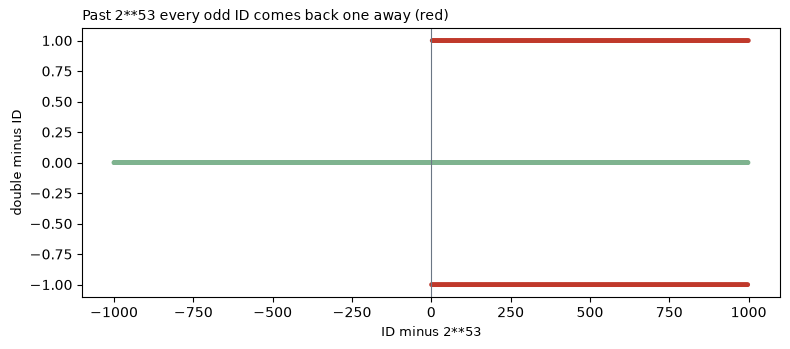

In [8]:
ids = make_ids()["boundary"]
off = [int(float(i)) - i for i in ids]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter([i - 2**53 for i in ids], off, s=6, color=["#c0392b" if o else "#7fb38f" for o in off])
ax.axvline(0, color="#6b7684", lw=0.8)
ax.set_xlabel("ID minus 2**53", fontsize=9)
ax.set_ylabel("double minus ID", fontsize=9)
ax.set_title("Past 2**53 every odd ID comes back one away (red)", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- One row decides the column type. Test the reader with a null, a `123.0` and an oversized value in the column.
- pandas `read_json` can report int64 while the values are wrong; `dtype='Int64'` and `dtype=str` do not fix it.
- Exact everywhere: `json`, `ujson`, pydantic, duckdb with an explicit HUGEINT column, `json` then a DataFrame.
- In JavaScript, send IDs as strings or use a reviver that reads `context.source` into BigInt.

## 8. Try your own

In [9]:
# my_id = 1801234567890123457                  # paste one of your IDs
# for name in READERS:
#     d = parse(name, [my_id], "one null")         # or "clean", "one 123.0", "one > 2**63", "one > 2**64"
#     print(f"{name:<21} {'raised' if d['raised'] else 'exact' if not d['wrong'] else 'WRONG'}")

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version lets you type an
ID and pick the odd row: `pip install -r requirements.txt && streamlit run app.py`.